## **X9**: TT - Sample Size of the Separability Analysis
* October 18°, 2026
#### ESCOM - IPN:

#### *B.S. in Computer Science*
> Miguel Alexander Sanchez Garcia

#### **0° Introduction**

Module 6 computes every separability metric on 200 training lesions per subset, stratified, with seed 42 (D-028). D-028 justified that size by the cost of the fidelity kernel: estimated pair by pair with *compute-uncompute* circuits, a 200 × 200 matrix at $k=12$ was projected at about 41 min in B1, and the number of pairs grows as $N(N-1)/2$. Module 5 then computed the kernels with the statevector shortcut, which takes 1.5 s per matrix (H-032). **In simulation the cost argument no longer binds**, and the M7 classifier uses the whole training split. This notebook asks the two questions that remain:

1. **Variance.** Would another set of 200 lesions change the conclusion of Module 6? Twenty stratified draws of 200 training lesions per subset.
2. **Size.** Does the conclusion depend on $N=200$? The same metrics on the full training split: 1,318 masses and 1,546 calcifications.

The official test split is not touched, as in Module 6. Only the pre-specified scale $c=1$ is analysed (D-029). The embedding metrics on the full training split were already in Module 6; here they are also computed on the twenty draws.

**What $N$ changes by construction.** Some metrics move with $N$ even when the geometry does not, so values at different $N$ are compared with care:

- **Effective dimension.** It is at most $N$, so it is compared as $d/N$.
- **Geometric difference.** Its reference value is $\sqrt{N}$ (Huang et al., 2021): 14.1 for 200 lesions, 36.3 for 1,318 and 39.3 for 1,546.
- **Alignment of a concentrated kernel.** The $N$ diagonal entries equal 1 and carry no label information; the label signal lives in the $N(N-1)$ off-diagonal entries. When those are tiny, as in C4 and C5 at $c=1$, the off-diagonal part gains weight as $N$ grows, and the excess over the permutation mean grows with it. Alignments are compared between kernels **at the same $N$**, never across sizes.
- **Fisher ratio.** The squared Mahalanobis distance between estimated class means is biased upwards in small samples: noise in the two means adds roughly $p\,(1/n_0+1/n_1)$, about 0.24–0.26 for $p=12$ and 200 lesions. The same metric is therefore lower on the full split for every condition.

The cost argument does hold on hardware, where the shortcut does not exist: section 5° quantifies it.

#### **1° Setup**

**a.** Libraries and parameters, the same as Module 6

In [1]:
import time
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import qiskit
from qiskit.circuit.library import pauli_feature_map, zz_feature_map
from qiskit_machine_learning.kernels import FidelityStatevectorKernel
from scipy.linalg import eigh
from sklearn.metrics import davies_bouldin_score
from sklearn.model_selection import StratifiedShuffleSplit

warnings.filterwarnings('ignore', category=FutureWarning)
SEED, N_PERM, N_DRAWS, N_SUB = 42, 1000, 20, 200
FINDINGS = ['mass', 'calcification']
TITLES = {'mass': 'Masses', 'calcification': 'Calcifications'}
CONDITIONS = ['C1', 'C2', 'C3', 'C4', 'C5']
QUANTUM = ['C4', 'C5']
KERNELS = ['K_C', 'C4', 'C5']
LAMBDAS = [1e-5, 1e-4, 1e-3, 1e-2, 0.025, 0.05, 0.1]      # Huang et al. (2021), eq. (L10)
MULTIPLIERS = [0.25, 0.5, 1, 2, 4, 8, 16, 32, 64]         # eq. (L11)
G_TRA_MAX = 0.045                                         # eq. (L9)
SHOTS = 1024                                              # RNF-05
X_COLUMNS = [f'x_{i:02d}' for i in range(1, 13)]
ROOT = Path('/Users/alexander_san/TT')
M4_DIR, M5_DIR = ROOT / 'Data/processed/m4', ROOT / 'Data/processed/m5'
RESULTS_DIR, FIG_DIR = ROOT / 'Code/results', ROOT / 'Docs/Figures'
COLORS = {'C1': '#eda100', 'C2': '#e87ba4', 'C3': '#2a78d6', 'K_C': '#2a78d6', 'C4': '#eb6834', 'C5': '#1baf7a'}
INK, NULL_GRAY = '#3d3d3a', '#b9b8b2'
plt.rcParams.update({'axes.spines.top': False, 'axes.spines.right': False, 'axes.grid': True,
                     'grid.alpha': 0.25, 'lines.linewidth': 2, 'lines.markersize': 8})
checks = []


def check(name, value, passed):
    checks.append({'check': name, 'value': float(value), 'passed': bool(passed)})


print(f'qiskit {qiskit.__version__} | {N_DRAWS} draws of {N_SUB} lesions | {N_PERM} permutations per sample')

qiskit 2.3.0 | 20 draws of 200 lesions | 1000 permutations per sample


**b.** The metrics, copied from Module 6 (cell 9) without changes

In [2]:
def sym(a):
    return (a + a.T) / 2


def normalize_trace(k):
    # Huang et al. assume Tr(K) = N (eq. 5)
    return k * len(k) / np.trace(k)


def psd_sqrt(k):
    # symmetric square root from the eigendecomposition; round-off negative eigenvalues are set to 0
    t, v = eigh(sym(k))
    return (v * np.sqrt(np.clip(t, 0, None))) @ v.T


def top_eigenvalue(m):
    return float(eigh(sym(m), eigvals_only=True)[-1])


def geometric_difference(kq, kc, lambdas):
    # g(K_C || K_Q): eq. (F19) for g_gen and eq. (F20) for g_tra; lambda = 0 gives the unregularized eq. (5)
    sq = psd_sqrt(kq)
    t, v = eigh(sym(kc))
    t = np.clip(t, 0, None)
    out = {}
    for lam in lambdas:
        if lam == 0:
            out[lam] = (np.sqrt(top_eigenvalue(sq @ ((v / t) @ v.T) @ sq)), 0.0) if t.min() > 0 else (np.inf, 0.0)
        else:
            gen = (v * (t / (t + lam) ** 2)) @ v.T          # sqrt(K_C) (K_C + lam I)^-2 sqrt(K_C)
            tra = (v * (1 / (t + lam) ** 2)) @ v.T          # (K_C + lam I)^-2
            out[lam] = (np.sqrt(top_eigenvalue(sq @ gen @ sq)), lam * np.sqrt(top_eigenvalue(sq @ tra @ sq)))
    return out


def center(k):
    # H K H with H = I - 11^T / n
    return k - k.mean(0) - k.mean(1)[:, None] + k.mean()


def alignment_with_null(k, y, perms):
    # uncentered and centered alignment for the observed labels y and for each permuted row of perms (labels +-1)
    n, kc = len(y), center(k)
    yc2 = np.sum((y - y.mean()) ** 2)        # ||H yy^T H||_F; the same for every permutation
    obs_u = y @ k @ y / (np.linalg.norm(k) * n)
    obs_c = y @ kc @ y / (np.linalg.norm(kc) * yc2)
    null_u = np.einsum('pi,ij,pj->p', perms, k, perms) / (np.linalg.norm(k) * n)
    null_c = np.einsum('pi,ij,pj->p', perms, kc, perms) / (np.linalg.norm(kc) * yc2)
    return obs_u, obs_c, null_u, null_c


def effective_dimension(k):
    # eq. (F12) with 1/(N-k+1)
    t = np.sort(np.clip(eigh(sym(normalize_trace(k)), eigvals_only=True), 0, None))[::-1]
    n = len(t)
    tails = np.cumsum(t[::-1])[::-1]             # tails[k-1] = sum of t_l for l >= k
    return float(np.sum(tails / (n - np.arange(n))))


def fisher_ratio(e, y01):
    # squared Mahalanobis distance between class means, pooled within-class covariance
    m0, m1 = e[y01 == 0].mean(0), e[y01 == 1].mean(0)
    r = np.vstack([e[y01 == 0] - m0, e[y01 == 1] - m1])
    diff = m1 - m0
    return float(diff @ np.linalg.solve(r.T @ r / (len(e) - 2), diff))


def linear_alignment(e, ypm):
    # centered alignment of the linear kernel E E^T for one or many +-1 label rows, without the N x N matrix
    ec, rows = e - e.mean(0), np.atleast_2d(ypm)
    num = np.sum((rows @ ec) ** 2, axis=1)
    return num / (np.linalg.norm(ec.T @ ec) * np.sum((rows - rows.mean(1, keepdims=True)) ** 2, axis=1))


def label_permutations(y01, n_perm, seed):
    rng = np.random.default_rng(seed)
    return np.array([rng.permutation(y01) for _ in range(n_perm)])

**c.** The geometric difference summarized as in Module 6 (cell 19): for each classical kernel of the paper's grid, the largest admissible $\lambda$; then the minimum over the suite. Only the largest eigenvalue is needed, so it is computed with `subset_by_index`, which gives the same value as the full decomposition of Module 6 at a fraction of the cost for $N\approx1{,}500$.

In [3]:
def top_eig(m):
    m = sym(m)
    return float(eigh(m, eigvals_only=True, subset_by_index=[len(m) - 1, len(m) - 1])[0])


def classical_suite(x):
    # eq. (L11): linear kernel on centered angles and nine Gaussian widths, gamma = m / (n Var[x])
    var, sq, xc = x.var(), ((x[:, None, :] - x[None, :, :]) ** 2).sum(-1), x - x.mean(0)
    suite = {'linear': normalize_trace(xc @ xc.T)}
    suite.update({f'gaussian {m:g}': np.exp(-(m / (x.shape[1] * var)) * sq) for m in MULTIPLIERS})
    return suite


def g_closest(kq, suite):
    sq, best = psd_sqrt(kq), (np.inf, None, np.nan)
    for name, kc in suite.items():
        t, v = eigh(sym(kc))
        t, admissible = np.clip(t, 0, None), None
        for lam in LAMBDAS:
            g_gen = np.sqrt(top_eig(sq @ ((v * (t / (t + lam) ** 2)) @ v.T) @ sq))
            g_tra = lam * np.sqrt(top_eig(sq @ ((v * (1 / (t + lam) ** 2)) @ v.T) @ sq))
            if g_tra < G_TRA_MAX:
                admissible = (g_gen, name, lam)          # lambdas ascend: keeps the largest admissible one
        if admissible and admissible[0] < best[0]:
            best = admissible
    return best


def family_a(x, y01, kernels):
    y, perms = 2 * y01 - 1, 2 * label_permutations(y01, N_PERM, SEED) - 1
    suite, rows = classical_suite(x), []
    for name, k in kernels.items():
        _, cen, _, nc = alignment_with_null(k, y, perms)
        row = {'kernel': name, 'n': len(y), 'kta_centered': cen, 'null_mean': nc.mean(), 'excess_centered': cen - nc.mean(),
               'p_centered': (1 + np.sum(nc >= cen)) / (1 + N_PERM), 'effective_dimension': effective_dimension(k),
               'median_off_diagonal': float(np.median(k[~np.eye(len(k), dtype=bool)]))}
        if name != 'K_C':
            row['g_min'], row['kernel_at_min'], row['lambda_at_min'] = g_closest(k, suite)
        rows.append(row)
    return rows


def family_b(embs, y01):
    return [{'condition': c, 'davies_bouldin': davies_bouldin_score(e, y01), 'fisher_j': fisher_ratio(e, y01),
             'kta_linear': float(linear_alignment(e, 2 * y01 - 1)[0])} for c, e in embs.items()]

#### **2° Kernels of the full training split**

**a.** The RBF kernel with the $\gamma$ of D-027 and the exact fidelity kernels of C4 and C5 for every training lesion. The 200 rows of Module 6 must give, inside these matrices, exactly the matrices stored by Module 5.

In [4]:
feature_maps = {'C4': zz_feature_map(12, reps=1), 'C5': pauli_feature_map(12, reps=1, paulis=['Y', 'ZZ'])}
cols = lambda c: [f'{c}_{i:02d}' for i in range(1, 13)]
data, timing = {}, []
for ft in FINDINGS:
    frame = pd.read_parquet(M4_DIR / f'x_{ft}.parquet')
    train = frame[frame.split.eq('train')].reset_index(drop=True)
    emb = pd.read_parquet(M5_DIR / f'emb_{ft}.parquet').set_index('case_id').loc[train.case_id]
    assert np.array_equal(emb.label.to_numpy(), train.label.to_numpy())
    x, y01 = train[X_COLUMNS].to_numpy(float), train.label.to_numpy(int)
    z = np.load(M5_DIR / f'kernels_{ft}.npz', allow_pickle=True)
    gamma = float(z['gamma'])
    sqd = ((x[:, None, :] - x[None, :, :]) ** 2).sum(-1)
    kernels = {'K_C': np.exp(-gamma * sqd)}
    for q, fm in feature_maps.items():
        t0 = time.perf_counter()
        kernels[q] = FidelityStatevectorKernel(feature_map=fm).evaluate(x)
        timing.append({'finding_type': ft, 'kernel': q, 'n': len(x), 'seconds': time.perf_counter() - t0})
    pos = pd.Series(np.arange(len(train)), index=train.case_id.astype(str)).loc[z['case_id'].astype(str)].to_numpy()
    for name, key in [('K_C', 'K_C'), ('C4', 'K_Q_C4_c1.0'), ('C5', 'K_Q_C5_c1.0')]:
        err = np.abs(kernels[name][np.ix_(pos, pos)] - z[key]).max()
        check(f'{ft}: the Module 6 rows of the full {name} equal the matrix of Module 5', err, err < 1e-12)
    data[ft] = {'x': x, 'y01': y01, 'kernels': kernels, 'design': pos,
                'emb': {c: emb[cols(c)].to_numpy(float) for c in CONDITIONS}}
    print(f'{ft:13s}: {len(x)} training lesions ({int(y01.sum())} malignant); C4 and C5 kernels in '
          + ', '.join(f"{r['seconds']:.0f} s" for r in timing if r['finding_type'] == ft))
timing = pd.DataFrame(timing)

mass         : 1318 training lesions (637 malignant); C4 and C5 kernels in 20 s, 21 s


calcification: 1546 training lesions (544 malignant); C4 and C5 kernels in 25 s, 27 s


**b.** The samples: the design subsample of Module 6, twenty stratified draws of 200 and the full split. The draws use `StratifiedShuffleSplit` with seed 42, the generator of Module 5; the first draw is expected to be the design subsample itself, and the other nineteen are new.

In [5]:
samples = {}
for ft in FINDINGS:
    d = data[ft]
    samples[(ft, 'design', -1)] = d['design']
    splitter = StratifiedShuffleSplit(n_splits=N_DRAWS, test_size=N_SUB, random_state=SEED)
    for draw, (_, idx) in enumerate(splitter.split(d['x'], d['y01'])):
        samples[(ft, 'draw', draw)] = idx
    samples[(ft, 'full train', -1)] = np.arange(len(d['y01']))
    same = set(samples[(ft, 'draw', 0)]) == set(d['design'])
    print(f"{ft:13s}: draw 0 is the design subsample: {same}; "
          f"overlap of the other draws with it: {np.mean([len(set(samples[(ft, 'draw', k)]) & set(d['design'])) for k in range(1, N_DRAWS)]):.0f} of {N_SUB} on average")

mass         : draw 0 is the design subsample: True; overlap of the other draws with it: 30 of 200 on average
calcification: draw 0 is the design subsample: True; overlap of the other draws with it: 25 of 200 on average


#### **3° Family A: kernel metrics at $c=1$**

**a.** Alignment with its permutation null, effective dimension and geometric difference for every sample. The full split is the slow part: a few minutes per subset.

In [6]:
rows_a = []
t0 = time.perf_counter()
for (ft, sample, draw), idx in samples.items():
    d = data[ft]
    sub = {k: v[np.ix_(idx, idx)] for k, v in d['kernels'].items()}
    for r in family_a(d['x'][idx], d['y01'][idx], sub):
        rows_a.append({'finding_type': ft, 'sample': sample, 'draw': draw, **r})
fam_a = pd.DataFrame(rows_a)
fam_a['d_over_n'] = fam_a.effective_dimension / fam_a.n
fam_a['sqrt_n'] = np.sqrt(fam_a.n)
fam_a.to_csv(RESULTS_DIR / 'X9_familia_a.csv', index=False)
print(f'{len(fam_a)} rows in {time.perf_counter() - t0:.0f} s')

132 rows in 198 s


**b.** The design subsample must reproduce Module 6 exactly: alignment, effective dimension and the minimum $g$ at $c=1$.

In [7]:
kta6 = pd.read_csv(RESULTS_DIR / '6_alineamiento_kernel.csv')
dim6 = pd.read_csv(RESULTS_DIR / '6_dimension_efectiva.csv')
g6 = pd.read_csv(RESULTS_DIR / '6_diferencia_geometrica_resumen.csv')
at_c1 = lambda df: df[df.c.isna() | (df.c == 1.0)]
for ft in FINDINGS:
    ours = fam_a[(fam_a.finding_type == ft) & (fam_a['sample'] == 'design')].set_index('kernel')
    ref_k, ref_d = at_c1(kta6[kta6.finding_type == ft]).set_index('kernel'), at_c1(dim6[dim6.finding_type == ft]).set_index('kernel')
    ref_g = g6[(g6.finding_type == ft) & (g6.c == 1.0)].set_index('map')
    err = max(np.abs(ours.loc[KERNELS, 'kta_centered'] - ref_k.loc[KERNELS, 'kta_centered']).max(),
              np.abs(ours.loc[KERNELS, 'excess_centered'] - ref_k.loc[KERNELS, 'excess_centered']).max())
    check(f'{ft}: design subsample reproduces the alignment of Module 6', err, err < 1e-12)
    err = np.abs(ours.loc[KERNELS, 'effective_dimension'] - ref_d.loc[KERNELS, 'effective_dimension']).max()
    check(f'{ft}: design subsample reproduces the effective dimension of Module 6', err, err < 1e-8)
    err = np.abs(ours.loc[QUANTUM, 'g_min'] - ref_g.loc[QUANTUM, 'g_min']).max()
    check(f'{ft}: design subsample reproduces the minimum g of Module 6', err, err < 1e-8)
display(pd.DataFrame(checks))

,check,value,passed
0,mass: the Module 6 rows of the full K_C equal ...,1.887379e-15,True
1,mass: the Module 6 rows of the full C4 equal t...,0.000000e+00,True
2,mass: the Module 6 rows of the full C5 equal t...,0.000000e+00,True
3,calcification: the Module 6 rows of the full K...,1.221245e-15,True
4,calcification: the Module 6 rows of the full C...,0.000000e+00,True
5,calcification: the Module 6 rows of the full C...,0.000000e+00,True
6,mass: design subsample reproduces the alignmen...,8.153200e-17,True
7,mass: design subsample reproduces the effectiv...,2.930989e-14,True
8,mass: design subsample reproduces the minimum ...,2.220446e-16,True
9,calcification: design subsample reproduces the...,1.110223e-16,True


**c.** Summary: the design value, the range over the twenty draws and the full split. The last columns count, over the draws, how often the RBF keeps more label-explained alignment than both quantum kernels and how often C5 is ahead of C4.

In [8]:
def summarize(df, metric):
    out = []
    for (ft, k), part in df.groupby(['finding_type', 'kernel'], sort=False):
        dr = part[part['sample'] == 'draw'][metric]
        out.append({'finding_type': ft, 'kernel': k, 'metric': metric,
                    'design': part.loc[part['sample'] == 'design', metric].iloc[0],
                    'draws_min': dr.min(), 'draws_median': dr.median(), 'draws_max': dr.max(),
                    'full_train': part.loc[part['sample'] == 'full train', metric].iloc[0]})
    return out


summary_a = pd.DataFrame(sum([summarize(fam_a[fam_a.kernel.isin(KERNELS if m != 'g_min' else QUANTUM)], m)
                              for m in ['excess_centered', 'p_centered', 'd_over_n', 'g_min']], []))
summary_a.to_csv(RESULTS_DIR / 'X9_resumen_familia_a.csv', index=False)
display(summary_a.round(4))

draws = fam_a[fam_a['sample'] == 'draw'].pivot_table(index=['finding_type', 'draw'], columns='kernel', values='excess_centered')
order = pd.DataFrame({'rbf_ahead_of_both': ((draws.K_C > draws.C4) & (draws.K_C > draws.C5)).groupby(level=0).mean(),
                      'c5_ahead_of_c4': (draws.C5 > draws.C4).groupby(level=0).mean(),
                      'largest_quantum_excess': draws[QUANTUM].max(axis=1).groupby(level=0).max(),
                      'smallest_rbf_excess': draws.K_C.groupby(level=0).min()})
display(order)
gq = fam_a[fam_a.kernel.isin(QUANTUM)]
print('largest g over every sample, as a fraction of sqrt(N):', f"{(gq.g_min / gq.sqrt_n).max():.3f}")
print('classical kernel at the minimum:', gq.kernel_at_min.value_counts().to_dict())

,finding_type,kernel,metric,design,draws_min,draws_median,draws_max,full_train
0,mass,K_C,excess_centered,0.0491,0.0190,0.0544,0.1241,0.0549
1,mass,C4,excess_centered,0.0030,0.0010,0.0027,0.0056,0.0061
2,mass,C5,excess_centered,0.0051,0.0008,0.0048,0.0107,0.0092
3,calcification,K_C,excess_centered,0.1515,0.0552,0.1432,0.1839,0.1483
4,calcification,C4,excess_centered,0.0062,0.0030,0.0060,0.0083,0.0180
5,calcification,C5,excess_centered,0.0066,0.0023,0.0077,0.0144,0.0199
6,mass,K_C,p_centered,0.0010,0.0010,0.0010,0.0280,0.0010
7,mass,C4,p_centered,0.0020,0.0010,0.0010,0.0460,0.0010
8,mass,C5,p_centered,0.0030,0.0010,0.0035,0.2358,0.0010
9,calcification,K_C,p_centered,0.0010,0.0010,0.0010,0.0010,0.0010


,rbf_ahead_of_both,c5_ahead_of_c4,largest_quantum_excess,smallest_rbf_excess
finding_type,,,,
calcification,1.0,0.70,0.014371,0.055153
mass,1.0,0.95,0.010664,0.018993


largest g over every sample, as a fraction of sqrt(N): 0.203
classical kernel at the minimum: {'gaussian 64': 82, 'gaussian 32': 6}


#### **4° Family B: embedding metrics**

**a.** Davies-Bouldin index, Fisher ratio and linear alignment of the five conditions on every sample. The full-split values must equal those of Module 6. On the draws only the values are computed, without permutations: the question here is whether the ordering of the conditions survives a change of sample.

In [9]:
emb6 = pd.read_csv(RESULTS_DIR / '6_metricas_embedding.csv')
rows_b = []
for (ft, sample, draw), idx in samples.items():
    d = data[ft]
    for r in family_b({c: e[idx] for c, e in d['emb'].items()}, d['y01'][idx]):
        rows_b.append({'finding_type': ft, 'sample': sample, 'draw': draw, 'n': len(idx), **r})
fam_b = pd.DataFrame(rows_b)
fam_b.to_csv(RESULTS_DIR / 'X9_familia_b.csv', index=False)
for ft in FINDINGS:
    for sample, ref_name in [('design', 'subsample'), ('full train', 'full train')]:
        ours = fam_b[(fam_b.finding_type == ft) & (fam_b['sample'] == sample)].set_index('condition')
        ref = emb6[(emb6.finding_type == ft) & (emb6['sample'] == ref_name)].set_index('condition')
        err = max(np.abs(ours.loc[CONDITIONS, m] - ref.loc[CONDITIONS, m]).max() for m in ['davies_bouldin', 'fisher_j', 'kta_linear'])
        check(f'{ft}: {sample} reproduces the embedding metrics of Module 6', err, err < 1e-10)

dr = fam_b[fam_b['sample'] == 'draw']
best_classical = dr[dr.condition.isin(['C1', 'C3'])].groupby(['finding_type', 'draw'])
best_quantum = dr[dr.condition.isin(QUANTUM)].groupby(['finding_type', 'draw'])
ahead = pd.DataFrame({
    'DB: best classical ahead': (best_classical.davies_bouldin.min() < best_quantum.davies_bouldin.min()).groupby(level=0).mean(),
    'Fisher: best classical ahead': (best_classical.fisher_j.max() > best_quantum.fisher_j.max()).groupby(level=0).mean(),
    'linear KTA: best classical ahead': (best_classical.kta_linear.max() > best_quantum.kta_linear.max()).groupby(level=0).mean()})
c45 = dr[dr.condition.isin(QUANTUM)].pivot_table(index=['finding_type', 'draw'], columns='condition', values=['davies_bouldin', 'fisher_j', 'kta_linear'])
ahead['DB: C5 ahead of C4'] = (c45[('davies_bouldin', 'C5')] < c45[('davies_bouldin', 'C4')]).groupby(level=0).mean()
ahead['Fisher: C5 ahead of C4'] = (c45[('fisher_j', 'C5')] > c45[('fisher_j', 'C4')]).groupby(level=0).mean()
ahead['linear KTA: C5 ahead of C4'] = (c45[('kta_linear', 'C5')] > c45[('kta_linear', 'C4')]).groupby(level=0).mean()
ahead.to_csv(RESULTS_DIR / 'X9_orden_familia_b.csv')
display(ahead.T)
display(fam_b[fam_b['sample'] != 'draw'].pivot_table(index=['finding_type', 'condition'], columns='sample',
                                                     values=['fisher_j', 'davies_bouldin']).round(3))
display(dr.groupby(['finding_type', 'condition'])[['fisher_j', 'davies_bouldin', 'kta_linear']].agg(['min', 'median', 'max']).round(3))

finding_type,calcification,mass
DB: best classical ahead,1.00,1.00
Fisher: best classical ahead,1.00,1.00
linear KTA: best classical ahead,1.00,1.00
DB: C5 ahead of C4,0.10,0.15
Fisher: C5 ahead of C4,0.35,0.85
linear KTA: C5 ahead of C4,0.10,0.35


davies_bouldin            fisher_j           
sample                          design full train   design full train
finding_type  condition                                              
calcification C1                 2.387      2.582    1.284      1.061
              C2                 2.387      2.582    1.284      1.061
              C3                 2.995      3.182    1.390      1.004
              C4                 6.890      5.283    0.399      0.423
              C5                 6.247     11.208    0.753      0.307
mass          C1                 4.301      4.626    0.669      0.454
              C2                 4.301      4.626    0.669      0.454
              C3                 5.564      5.731    0.781      0.441
              C4                 5.898     10.323    0.449      0.128
              C5                13.346     16.856    0.668      0.212

fisher_j               davies_bouldin                  \
                             min median    max            min  median     max   
finding_type  condition                                                         
calcification C1           0.829  1.335  1.850          2.283   2.533   3.960   
              C2           0.829  1.335  1.850          2.283   2.533   3.960   
              C3           0.745  1.287  1.741          2.739   3.149   5.076   
              C4           0.255  0.594  1.002          3.280   5.712   9.538   
              C5           0.235  0.546  1.168          6.247   9.589  13.522   
mass          C1           0.426  0.698  1.237          2.845   4.236   7.269   
              C2           0.426  0.698  1.237          2.845   4.236   7.269   
              C3           0.403  0.663  1.096          3.573   5.342   8.125   
              C4           0.146  0.358  0.676          5.403   8.558  13.972   
              C5           0.260  0.491  0.668          8.120  10.346  16.088   

                        kta_linear                
                               min median    max  
finding_type  condition                           
calcification C1             0.079  0.166  0.202  
              C2             0.079  0.166  0.202  
              C3             0.065  0.153  0.194  
              C4             0.013  0.040  0.102  
              C5             0.009  0.018  0.041  
mass          C1             0.027  0.073  0.148  
              C2             0.027  0.073  0.148  
              C3             0.030  0.064  0.134  
              C4             0.009  0.022  0.051  
              C5             0.008  0.020  0.032

#### **5° What the size would cost on hardware**

On a quantum computer each kernel entry is a separate *compute-uncompute* circuit, repeated for many shots, and the statevector shortcut does not exist (H-032). The kernel is symmetric with a unit diagonal, so a matrix needs $N(N-1)/2$ circuits. The simulated time uses the cost per pair measured in B1 for the ZZ map at $k=12$ with `FidelityQuantumKernel`, the same figure behind the 41 min of D-028; the hardware columns count circuits and shots only, without queue or calibration times. Module 6 needs two matrices per subset at $c=1$ and twelve with the scale sweep of D-029.

In [10]:
b1 = pd.read_csv(RESULTS_DIR / 'B1_benchmark_kernel.csv')
s_pair = b1[(b1.feature_map == 'zz') & (b1.k == 12)].s_per_pair.mean()
cost_rows = []
for label, n in [('subsample', N_SUB), ('mass, full train', len(data['mass']['y01'])),
                 ('calcification, full train', len(data['calcification']['y01']))]:
    pairs = n * (n - 1) // 2
    cost_rows.append({'sample': label, 'n': n, 'circuits_per_matrix': pairs, 'shots_per_matrix': pairs * SHOTS,
                      'simulated_compute_uncompute_hours_per_matrix': pairs * s_pair / 3600,
                      'hours_two_maps_c1': 2 * pairs * s_pair / 3600, 'hours_twelve_matrices': 12 * pairs * s_pair / 3600})
cost = pd.DataFrame(cost_rows)
cost.to_csv(RESULTS_DIR / 'X9_costo_hardware.csv', index=False)
print(f'B1 cost per pair, ZZ map, k = 12: {s_pair * 1000:.0f} ms')
display(cost.round(1))
display(timing)

B1 cost per pair, ZZ map, k = 12: 140 ms


,sample,n,circuits_per_matrix,shots_per_matrix,simulated_compute_uncompute_hours_per_matrix,hours_two_maps_c1,hours_twelve_matrices
0,subsample,200,19900,20377600,0.8,1.5,9.3
1,"mass, full train",1318,867903,888732672,33.7,67.5,404.8
2,"calcification, full train",1546,1194285,1222947840,46.4,92.8,557.0


,finding_type,kernel,n,seconds
0,mass,C4,1318,19.529162
1,mass,C5,1318,20.694124
2,calcification,C4,1546,25.355007
3,calcification,C5,1546,27.462488


#### **6° Figure**

Each column is one metric of family A at $c=1$. The dots are the twenty draws of 200 lesions, the black ring marks the design subsample of Module 6 and the diamond the full training split. In the middle column $g$ is divided by $\sqrt{N}$ so that both sizes share one axis: Huang et al. read a potential advantage only when $g$ is of the order of $\sqrt{N}$, that is, near 1 on this axis.

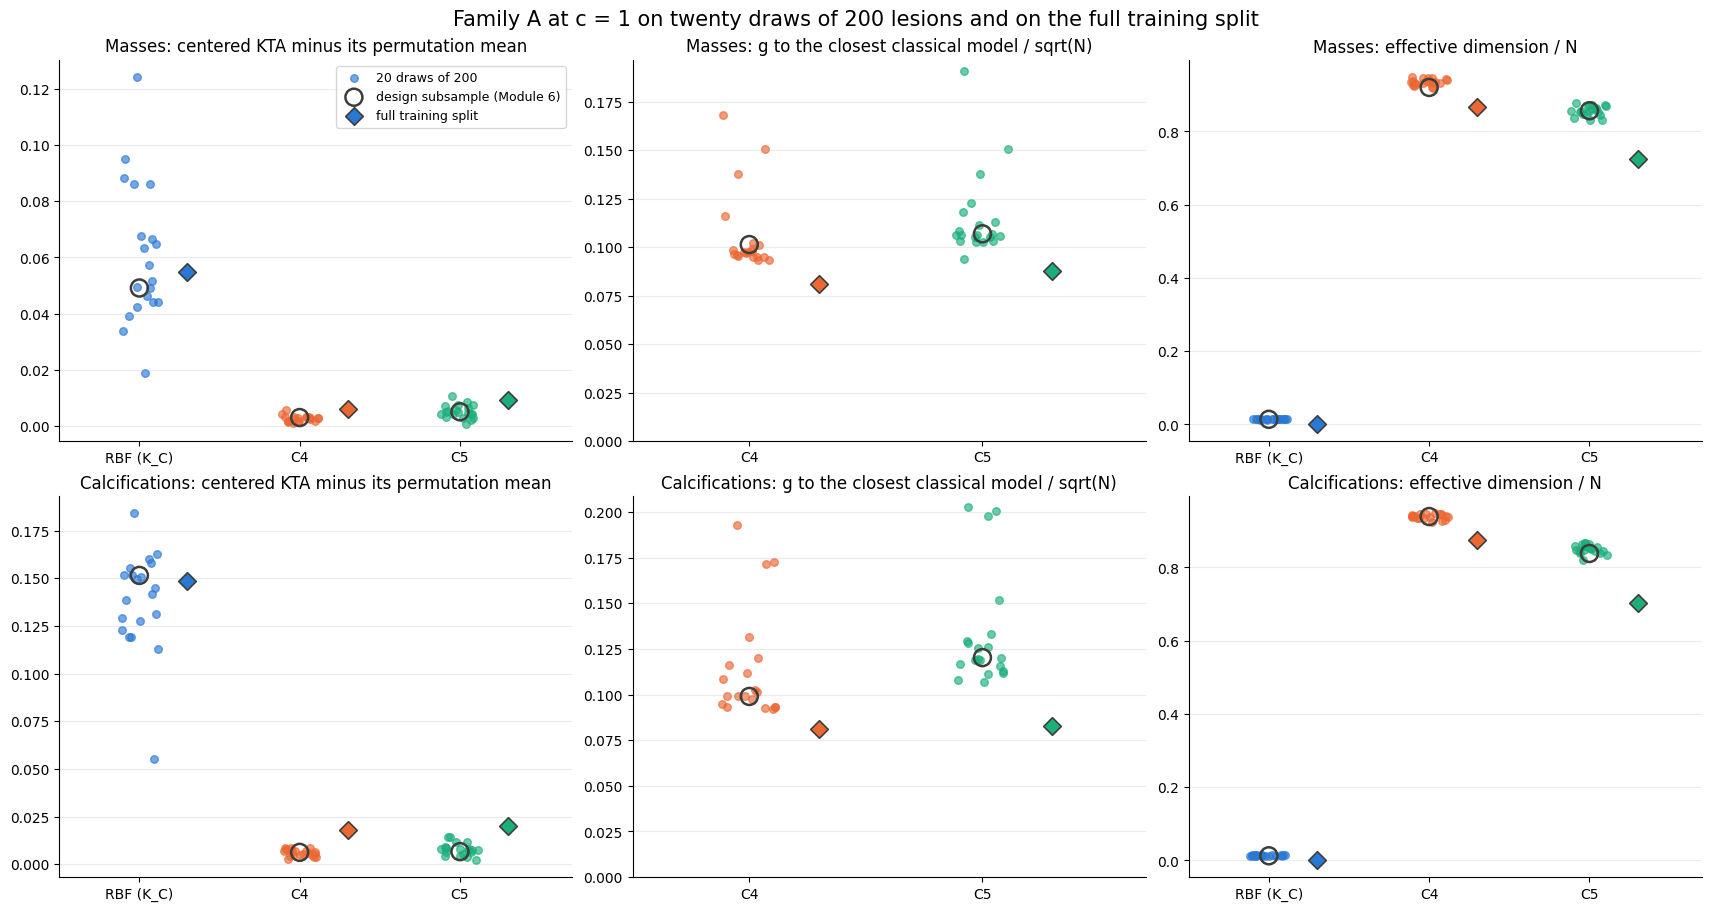

In [11]:
metrics = [('excess_centered', 'centered KTA minus its permutation mean', KERNELS),
           ('g_over_sqrt_n', 'g to the closest classical model / sqrt(N)', QUANTUM),
           ('d_over_n', 'effective dimension / N', KERNELS)]
fam_a['g_over_sqrt_n'] = fam_a.g_min / fam_a.sqrt_n
rng = np.random.default_rng(SEED)
fig, axes = plt.subplots(2, 3, figsize=(17, 9), constrained_layout=True)
for row, ft in enumerate(FINDINGS):
    for col, (metric, label, kernels) in enumerate(metrics):
        ax = axes[row, col]
        for i, k in enumerate(kernels):
            part = fam_a[(fam_a.finding_type == ft) & (fam_a.kernel == k)]
            dr = part[part['sample'] == 'draw'][metric]
            ax.scatter(i + rng.uniform(-0.12, 0.12, len(dr)), dr, s=30, color=COLORS[k], alpha=0.65,
                       label='20 draws of 200' if i == 0 and row == 0 and col == 0 else None)
            ax.scatter(i, part.loc[part['sample'] == 'design', metric], s=150, facecolor='none', edgecolor=INK, linewidth=1.8,
                       label='design subsample (Module 6)' if i == 0 and row == 0 and col == 0 else None, zorder=3)
            ax.scatter(i + 0.3, part.loc[part['sample'] == 'full train', metric], marker='D', s=80, color=COLORS[k],
                       edgecolor=INK, linewidth=1.2, label='full training split' if i == 0 and row == 0 and col == 0 else None, zorder=3)
        ax.set_xticks(range(len(kernels)), ['RBF (K_C)' if k == 'K_C' else k for k in kernels])
        ax.set(title=f'{TITLES[ft]}: {label}', xlim=(-0.5, len(kernels) - 0.3))
        ax.grid(axis='x', visible=False)
        if metric == 'g_over_sqrt_n':
            ax.set_ylim(0, None)
axes[0, 0].legend(fontsize=9, loc='upper right')
fig.suptitle('Family A at c = 1 on twenty draws of 200 lesions and on the full training split', fontsize=15)
fig.savefig(FIG_DIR / 'X9_sample_size.png', dpi=180, bbox_inches='tight')
plt.show()

#### **7° Verifications**

In [12]:
verifications = pd.DataFrame(checks)
verifications.to_csv(RESULTS_DIR / 'X9_verificaciones.csv', index=False)
display(verifications)
print(f'Checks passed: {int(verifications.passed.sum())}/{len(verifications)}')

,check,value,passed
0,mass: the Module 6 rows of the full K_C equal ...,1.887379e-15,True
1,mass: the Module 6 rows of the full C4 equal t...,0.000000e+00,True
2,mass: the Module 6 rows of the full C5 equal t...,0.000000e+00,True
3,calcification: the Module 6 rows of the full K...,1.221245e-15,True
4,calcification: the Module 6 rows of the full C...,0.000000e+00,True
5,calcification: the Module 6 rows of the full C...,0.000000e+00,True
6,mass: design subsample reproduces the alignmen...,8.153200e-17,True
7,mass: design subsample reproduces the effectiv...,2.930989e-14,True
8,mass: design subsample reproduces the minimum ...,2.220446e-16,True
9,calcification: design subsample reproduces the...,1.110223e-16,True


Checks passed: 16/16


#### **8° Consequence**

**1. The conclusion of Module 6 does not depend on which 200 lesions were drawn.**

- The design subsample is the first of the twenty draws: same generator, same seed. The other nineteen share on average only 25–30 of its 200 lesions.
- In all twenty draws of both subsets, the RBF kernel keeps more label-explained alignment than both quantum kernels. The ranges do not overlap: the smallest RBF excess, 0.019 in masses and 0.055 in calcifications, is above the largest quantum one, 0.011 and 0.014.
- The geometric difference stays between 1.31 and 2.87, at most 0.20 of $\sqrt{N}=14.1$. The closest classical model is always one of the two narrowest Gaussians of the grid (64 in 82 of 88 cases, 32 in the rest).
- The effective dimension of C4 and C5 stays between 0.82 and 0.95 of $N$: the regime *"all inputs are too far apart"* in every draw.
- In family B the best classical condition (C1 or C3) is ahead of both quantum ones in all twenty draws, for the Davies-Bouldin index, the Fisher ratio and the linear alignment.
- The design subsample is a typical draw, not a favourable one: its values fall inside the cloud of the other draws in every panel of the figure.

**2. Nor does it depend on $N=200$.** On the full training split (1,318 masses, 1,546 calcifications):

- The label-explained alignment is 0.055 for the RBF against 0.006 (C4) and 0.009 (C5) in masses, and 0.148 against 0.018 and 0.020 in calcifications, all with $p=0.001$.
- The quantum excess doubles or triples with respect to the subsample while the RBF one does not move. This is the effect of $N$ on a concentrated kernel described in 0°: more off-diagonal pairs, each with a tiny overlap. The quantum kernels still keep only 11–17 % (masses) and 12–13 % (calcifications) of the RBF alignment.
- $g$ rises to 2.9–3.3, but $\sqrt{N}$ rises to 36–39: the ratio falls to about 0.08.
- $d/N$ falls to 0.87 (C4) and 0.70–0.72 (C5), still far from the 0.002 of the RBF.

**3. What does depend on the sample.**

- **The significance of the smallest effects.** C5 in masses has $p$ up to 0.24 in some draws; on the full split every $p$ is 0.001. A non-significant quantum excess at $N=200$ is a matter of power, not a sign of no structure.
- **The order of C4 and C5.** C5 has more kernel alignment than C4 in 95 % of the mass draws and 70 % of the calcification draws, while in family B the winner changes with the metric (C5 ahead in Fisher in 85 % of the mass draws, but in Davies-Bouldin in only 15 %). "C4 against C5, no winner" (H-040) is the reading that survives.
- **The absolute values.** Alignments, $g$ and $d$ change with $N$ by construction, and the Fisher ratio is about 0.24–0.27 higher on the draws than on the full split for C1, as the small-sample bias predicts. Values are compared between conditions at the same $N$.

**4. Why 200 remains the size of the main analysis.** It was fixed before the data were seen (D-028), and it is the size at which the experiment could be repeated with the physical protocol:

| | Circuits per matrix | Shots at 1,024 | Simulated *compute-uncompute* |
|---|---|---|---|
| 200 lesions | 19,900 | 20 million | 0.8 h per matrix |
| 1,318 masses | 867,903 | 889 million | 34 h |
| 1,546 calcifications | 1,194,285 | 1,223 million | 46 h |

With the two maps at $c=1$ that is 67 h and 93 h on the full split; with the twelve matrices of the scale sweep, 405 h and 557 h. The statevector shortcut that computed the full split here in about 20 s per matrix does not exist on hardware (H-032). The size does not cure the concentration either: at $c=1$, with 1,024 shots, between 16 and 74 % of the entries would read exactly 0 (H-052), whatever $N$ is.

**Limits.** Only $c=1$ and $k=12$; the twenty draws are not independent samples of a population but resamples of the same training split, so they measure the variability due to the choice of lesions, not the generalization to other patients.